Importamos los paquetes necesarios

In [1]:
#!/usr/bin/python3
import os
import sys
from collections import deque

import cv2
import joblib
import keras
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
import torch
from joblib import Parallel, delayed
from mtcnn import MTCNN
from skimage.feature import hog
from sklearn.decomposition import PCA
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from tensorflow.keras import layers, models


I0000 00:00:1795634094.053012   31812 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795634094.301787   31812 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795634096.014043   31812 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [13]:
os.environ["KERAS_BACKEND"] = "torch"

try:
    tf.config.set_visible_devices([], "GPU")
except Exception:
    pass

# Selección de dispositivo: GPU si existe, si no CPU
if torch.cuda.is_available():
    DEVICE = "gpu:0"
    print("Usando GPU:", torch.cuda.get_device_name(0))
else:
    DEVICE = "cpu"
    print("No se detectó GPU, usando CPU")

No se detectó GPU, usando CPU


Entrenamiento 1

Detección de características

In [14]:
EXTENSIONES = (".png", ".jpg", ".jpeg")
IMG_SIZE = 112


# Recibir una cara en escala de grises y devolver el vector HOG.
def hog_cara(gris):
    gris = cv2.resize(gris, (IMG_SIZE, IMG_SIZE))
    return hog(
        gris,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
    )


def _procesar(ruta):
    img = cv2.imread(ruta, cv2.IMREAD_GRAYSCALE)
    return None if img is None else hog_cara(img)

Carga de datos

In [15]:
def cargar(carpeta, clases=None):
    if clases is None:
        clases = sorted(
            d for d in os.listdir(carpeta) if os.path.isdir(os.path.join(carpeta, d))
        )
    rutas, etiquetas = [], []
    for i, c in enumerate(clases):
        d = os.path.join(carpeta, c)
        for f in os.listdir(d):
            if f.lower().endswith(EXTENSIONES):
                rutas.append(os.path.join(d, f))
                etiquetas.append(i)
    print(f"Extrayendo HOG de {len(rutas)} imágenes en {carpeta}...")
    feats = Parallel(n_jobs=-1)(delayed(_procesar)(r) for r in rutas)
    ok = [i for i, f in enumerate(feats) if f is not None]
    X = np.array([feats[i] for i in ok])
    y = np.array([etiquetas[i] for i in ok])
    return X, y, clases


def localizar_raiz(root):
    if not os.path.isdir(root):
        sys.exit(
            f"No existe la carpeta '{root}'. Ejecuta el script desde el "
            f"directorio que la contiene o pasa la ruta completa."
        )
    for _ in range(3):
        subs = [d for d in os.listdir(root) if os.path.isdir(os.path.join(root, d))]
        if "train" in subs or len(subs) != 1:
            break
        root = os.path.join(root, subs[0])
    print("Usando carpeta:", root)
    print("Contiene:", sorted(os.listdir(root))[:15])
    return root


def cargar_todo(root):
    root = localizar_raiz(root)
    train_dir = os.path.join(root, "train")
    if os.path.isdir(train_dir):
        X_tr, y_tr, clases = cargar(train_dir)
        test_dir = next(
            (
                os.path.join(root, n)
                for n in ("test", "validation")
                if os.path.isdir(os.path.join(root, n))
            ),
            None,
        )
        if test_dir:
            X_te, y_te, _ = cargar(test_dir, clases)
        else:
            X_tr, X_te, y_tr, y_te = train_test_split(
                X_tr, y_tr, test_size=0.2, stratify=y_tr, random_state=42
            )
    else:
        X, y, clases = cargar(root)
        X_tr, X_te, y_tr, y_te = train_test_split(
            X, y, test_size=0.2, stratify=y, random_state=42
        )
    return X_tr, X_te, y_tr, y_te, clases


Entrenamiento de la parte 1

Usando carpeta: dataset
Contiene: ['test', 'train', 'validation']
Extrayendo HOG de 66379 imágenes en dataset/train...
Extrayendo HOG de 3573 imágenes en dataset/test...
Clases: ['angry', 'contempt', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'suprise']
Train: (66379, 6084) Test: (3573, 6084)
Imágenes por clase (train): {'angry': np.int64(8000), 'contempt': np.int64(8000), 'disgust': np.int64(8000), 'fear': np.int64(8000), 'happy': np.int64(8000), 'neutral': np.int64(10379), 'sad': np.int64(8000), 'suprise': np.int64(8000)}
Fitting 3 folds for each of 9 candidates, totalling 27 fits
Mejores parámetros: {'svc__C': 10, 'svc__gamma': 'scale'}
              precision    recall  f1-score   support

       angry       0.62      0.57      0.59       322
    contempt       0.73      0.27      0.39        30
     disgust       0.60      0.43      0.50        21
        fear       0.59      0.33      0.42        98
       happy       0.79      0.79      0.79       929
     neutral       0.68 

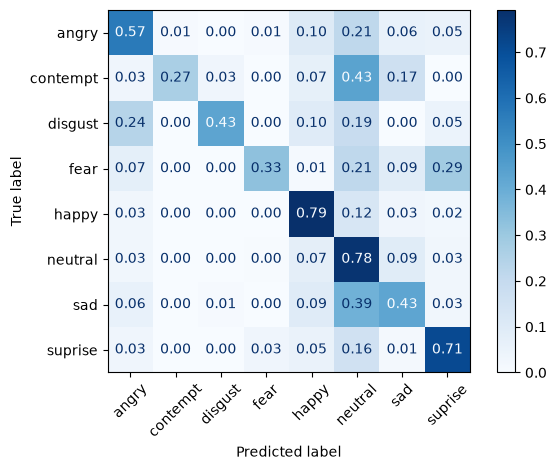

Modelo guardado en emociones_clasico.joblib


In [ ]:
N_PCA = 150


def main(root="dataset"):
    os.makedirs("train1", exist_ok=True)
    X_tr, X_te, y_tr, y_te, clases = cargar_todo(root)
    print("Clases:", clases)
    print("Train:", X_tr.shape, "Test:", X_te.shape)
    print("Imágenes por clase (train):", dict(zip(clases, np.bincount(y_tr))))

    pipe = make_pipeline(
        StandardScaler(),
        PCA(n_components=N_PCA, svd_solver="randomized", random_state=0),
        SVC(kernel="rbf", class_weight="balanced"),
    )

    # Búsqueda de hiperparámetros sobre una submuestra (para que sea rápido)
    n = min(5000, len(X_tr))
    idx = np.random.RandomState(0).choice(len(X_tr), n, replace=False)
    grid = GridSearchCV(
        pipe,
        {"svc__C": [1, 10, 100], "svc__gamma": ["scale", 0.001, 0.0001]},
        cv=3,
        scoring="f1_macro",
        n_jobs=1,
        verbose=1,
    )
    grid.fit(X_tr[idx], y_tr[idx])
    print("Mejores parámetros:", grid.best_params_)

    # Entrenamiento final con todos los datos de train
    pipe.set_params(**grid.best_params_)
    pipe.fit(X_tr, y_tr)

    # Evaluación
    pred = pipe.predict(X_te)
    print(classification_report(y_te, pred, target_names=clases, zero_division=0))
    print("F1 macro:", f1_score(y_te, pred, average="macro"))

    ConfusionMatrixDisplay.from_predictions(
        y_te,
        pred,
        display_labels=clases,
        xticks_rotation=45,
        normalize="true",
        cmap="Blues",
        values_format=".2f",
    )
    plt.tight_layout()
    plt.savefig("./train1/matriz_confusion_clasico.png", dpi=150)
    plt.show()

    joblib.dump({"modelo": pipe, "clases": clases}, "./train1/emociones_clasico.joblib")
    print("Modelo guardado en train1/emociones_clasico.joblib")

main("dataset")

Entrenamiento 2

In [ ]:
os.makedirs("train2", exist_ok=True)
train = tf.keras.utils.image_dataset_from_directory(
    "./dataset/train",
    image_size=(112, 112),
    color_mode="grayscale",
    batch_size=64,
    label_mode="categorical",
)

val = tf.keras.utils.image_dataset_from_directory(
    "./dataset/validation",
    image_size=(112, 112),
    color_mode="grayscale",
    batch_size=64,
    label_mode="categorical",
    shuffle=False,
)

with keras.device(DEVICE):
    model = models.Sequential(
        [
            layers.Input(shape=(112, 112, 1)),
            layers.Rescaling(1 / 255),
            layers.RandomFlip("horizontal"),
            layers.RandomRotation(0.05),
            layers.Conv2D(32, 3, activation="relu"),
            layers.MaxPooling2D(),
            layers.Conv2D(64, 3, activation="relu"),
            layers.MaxPooling2D(),
            layers.Conv2D(128, 3, activation="relu"),
            layers.Flatten(),
            layers.Dropout(0.4),
            layers.Dense(128, activation="relu"),
            layers.Dense(8, activation="softmax"),
        ]
    )

    model.compile("adam", "categorical_crossentropy", metrics=["accuracy"])
    model.fit(
        train,
        validation_data=val,
        epochs=30,
        callbacks=[
            keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)
        ],
    )
    model.save("./train2/emociones.keras")

    y_pred = np.argmax(model.predict(val), axis=1)

# Evaluación
clases = val.class_names

y_true = np.concatenate([np.argmax(y, axis=1) for _, y in val])

print(classification_report(y_true, y_pred, target_names=clases, zero_division=0))
print("F1 macro:", f1_score(y_true, y_pred, average="macro"))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=clases,
    normalize="true",
    xticks_rotation=45,
    cmap="Blues",
    values_format=".2f",
)
plt.tight_layout()
plt.savefig("./train2/matriz_confusion_cnn.png", dpi=150)
plt.show()

Detección en vivo con el modelo del entrenamiento 2 (CNN)

In [ ]:
MODELO_RUTA = "train2/emociones.keras"
DATASET_TRAIN = "dataset/train"
VENTANA = 8
MARGEN = 0.10

modelo = keras.saving.load_model(MODELO_RUTA)

CLASES = sorted(d for d in os.listdir(DATASET_TRAIN) if os.path.isdir(os.path.join(DATASET_TRAIN, d)))
assert modelo.output_shape[-1] == len(CLASES)
print("Clases:", CLASES)

NOMBRES = {
    "angry" : "Enfadado",
    "contempt": "Desprecio",
    "disgust": "Asco",
    "happy": "Feliz",
    "neutral": "Neutral",
    "sad": "Triste",
    "suprise": "Sorpresa",
}

COLORES = {
    "angry": (60, 60, 255),
    "contempt": (180, 180, 180),
    "disgust": (60, 180, 60),
    "fear": (200, 100, 200),
    "happy": (0, 215, 255),
    "neutral": (0, 215, 255),
    "sad": (255, 150, 60),
    "suprise": (0, 165, 255)
}

haar = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
if haar.empty():
    print("AVISO: no se pudo cargar el clasificador Haar de OpenCV")

try:
    mtcnn = MTCNN()
except Exception as e:
    mtcnn = None
    print("MTCNN no disponible, solo se podrá usar Harr:", e)

Funciones auxiliares: detección, preparación de la cara y reacción (emoji)

In [ ]:
def detectar(frame, gris, detector):
    if detector == "mtcnn" and mtcnn is not None:
        res = mtcnn.detect_faces(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        return [
            (tuple(max(0, int(v)) for v in r["box"]), r["keypoints"])
            for r in res
            if r["confidence"] > 0.9
        ]
    if haar.empty():
        return []
    caras = haar.detectMultiScale(
        gris, scaleFactor=1.2, minNeighbors=5, minSize=(60, 60)
    )
    return [(tuple(int(v) for v in c), None) for c in caras]


def preparar_cara(gris, caja, kp):
    x, y, w, h = caja
    if kp is not None:
        (lx, ly), (rx, ry) = sorted(
            [kp["left_eye"], kp["right_eye"]], key=lambda p: p[0]
        )
        angulo = float(np.degrees(np.arctan2(ry - ly, rx - lx)))
        M = cv2.getRotationMatrix2D(((lx + rx) / 2, (ly + ry) / 2), angulo, 1.0)
        gris = cv2.warpAffine(gris, M, (gris.shape[1], gris.shape[0]))
    mx, my = int(w * MARGEN), int(h * MARGEN)
    x0, y0 = max(0, x - mx), max(0, y - my)
    x1, y1 = min(gris.shape[1], x + w + mx), min(gris.shape[0], y + h + my)
    cara = gris[y0:y1, x0:x1]
    if cara.size == 0:
        return None
    return cv2.resize(cara, (112, 112))[None, ..., None].astype(np.float32)


def dibjuar_emoji(img, centro, r, emocion):
    cx, cy = centro
    negro = (0, 0, 0)
    cv2.circle(img, centro, r, COLORES.get(emocion, (0, 215, 255)), -1)
    cv2.circle(img, centro, r, negro, 2)
    dx, ey = int(r * 0.38), cy - int(r * 0.2)
    sorprendido = emocion in ("fear", "suprise", "surprise")
    ojo = max(2, int(r * (0.15 if sorprendido else 0.1)))
    for s in (-1, 1):
        cv2.circle(img, (cx + s * dx, ey), ojo, negro, -1)
        if emocion == "angry":
            cv2.line(
                img,
                (cx + s * (dx + int(r * 0.2)), ey - int(r * 0.3)),
                (cx + s * (dx - int(r * 0.2)), ey - int(r * 0.1)),
                negro,
                2,
            )

    # La boca se dibuja una sola vez, fuera del bucle de los ojos
    my, ax = cy + int(r * 0.4), int(r * 0.45)
    if emocion == "happy":
        cv2.ellipse(
            img, (cx, cy + int(r * 0.1)), (ax, int(r * 0.45)), 0, 20, 160, negro, 3
        )
    elif emocion in ("sad", "angry"):
        cv2.ellipse(
            img, (cx, cy + int(r * 0.75)), (ax, int(r * 0.3)), 0, 200, 340, negro, 3
        )
    elif emocion == "suprise":
        cv2.circle(img, (cx, my), int(r * 0.18), negro, -1)
    elif emocion == "fear":
        cv2.ellipse(img, (cx, my), (int(r * 0.15), int(r * 0.22)), 0, 0, 360, negro, -1)
    elif emocion == "disgust":
        cv2.line(
            img, (cx - ax, my + int(r * 0.1)), (cx + ax, my - int(r * 0.1)), negro, 3
        )
    elif emocion == "contempt":
        cv2.line(img, (cx - int(r * 0.3), my), (cx + int(r * 0.3), my), negro, 3)
        cv2.line(
            img,
            (cx + int(r * 0.3), my),
            (cx + int(r * 0.45), my - int(r * 0.12)),
            negro,
            3,
        )
    else:
        cv2.line(img, (cx - ax, my), (cx + ax, my), negro, 3)


def dibujar_probs(img, probs):
    for i, (c, p) in enumerate(zip(CLASES, probs)):
        y = 20 + i * 18
        cv2.putText(
            img,
            NOMBRES.get(c, c),
            (8, y + 4),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.4,
            (255, 255, 255),
            1,
        )
        cv2.rectangle(
            img,
            (85, y - 6),
            (85 + int(float(p) * 120), COLORES.get(c, (0, 215, 255))),
            -1,
        )

Bucle de cámara

In [ ]:
def demo(camara=0, detector="haar"):
    cap = cv2.VideoCapture(camara)
    if not cap.isOpened():
        print("No se pudo abrir la cámara", camara)
        return
    historial = {}
    mostrar_lm = True
    try:
        while True:
            ok, frame = cap.read()
            if not ok:
                break
            frame = cv2.flip(frame, 1)
            gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
            caras = sorted(detectar(frame, gris, detector), key=lambda c: c[0][0])
            for k in [k for k in historial if k >= len(caras)]:
                del historial[k]

            panel, area_max = None, 0
            for i, ((x, y, w, h), kp) in enumerate(caras):
                entrada = preparar_cara(gris, (x, y, w, h), kp)
                if entrada is None:
                    continue
                p = keras.ops.convert_to_numpy(modelo(entrada, training=False))[0]
                hist = historial.setdefault(i, deque(maxlen=VENTANA))
                hist.append(p)
                media = np.mean(hist, axis=0)
                emocion = CLASES[int(np.argmax(media))]
                color = COLORES.get(emocion, (0, 215, 255))

                cv2.rectangle(frame, (x, y), (x + w, y + h), color, 2)
                cv2.putText(
                    frame,
                    f"{NOMBRES.get(emocion, emocion)} {media.max() * 100:.0f}%",
                    (x, y + h + 22),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.7,
                    color,
                    2,
                )

                r = max(20, w // 4)
                cx = min(max(x + w // 2, r), frame.shape[1] - r)
                cy = y - r - 8
                if cy < r:
                    cy = min(y + h + r + 30, frame.shape[0] - r)
                dibjuar_emoji(frame, (int(cx), int(cy)), int(r), emocion)

                if mostrar_lm and kp is not None:
                    for punto in kp.values():
                        cv2.circle(
                            frame, tuple(int(v) for v in punto), 3, (0, 255, 0), -1
                        )
                if w * h > area_max:
                    panel, area_max = media, w * h

            if panel is not None:
                dibujar_probs(frame, panel)
            cv2.putText(
                frame,
                f"Detector: {detector} | d: cambiar | e: landmarks | ESC: salir",
                (8, frame.shape[0] - 10),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.45,
                (255, 255, 255),
                1,
            )
            cv2.imshow("Emociones", frame)

            tecla = cv2.waitKey(1) & 0xFF
            if tecla == 27:
                break
            elif tecla == ord("d"):
                detector = (
                    "mtcnn" if (detector == "haar" and mtcnn is not None) else "haar"
                )
                historial.clear()
            elif tecla == ord("e"):
                mostrar_lm = not mostrar_lm
    finally:
        cap.release()
        cv2.destroyAllWindows()
        cv2.waitKey(1)


demo()